## **Food Delivery Delay Analysis**

**Setup and data loading**

In [1]:
import os
import re
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from google.colab import files

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

OUTPUT_DIR = "food_delivery_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

All libraries imported successfully!
TensorFlow version: 2.21.0


In [2]:
import os
import pandas as pd
from google.colab import files

default_path = "train.csv"

if os.path.exists(default_path):
    print(f"Found '{default_path}' in the current directory. Loading it directly...")
    filename = default_path

else:
    print("train.csv not found in the current directory. Please upload train.csv:")
    uploaded = files.upload()

    csv_files = [
        f for f in uploaded
        if f.lower().endswith(".csv")
    ]

    if not csv_files:
        raise ValueError("No CSV file uploaded. Please upload train.csv.")

    matching_files = [
        f for f in csv_files
        if os.path.basename(f).lower() == "train.csv"
    ]

    if not matching_files:
        raise ValueError(
            "train.csv was not found among the uploaded files. "
            "Please upload the correct training dataset."
        )

    filename = matching_files[0]

df = pd.read_csv(filename)

df.columns = df.columns.astype(str).str.strip()

print("Dataset loaded successfully!")
print("File:", filename)
print("Dataset shape:", df.shape)
print("Number of columns:", len(df.columns))

print("\nColumn names:")
print(df.columns.tolist())

display(df.head())


Found 'train.csv' in the current directory. Loading it directly...
Dataset loaded successfully!
File: train.csv
Dataset shape: (45593, 20)
Number of columns: 20

Column names:
['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)']


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


**DATA PREPROCESSING**

In [3]:
print("========== DATASET INFORMATION ==========")
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nDataset information:")
df.info()


missing_tokens = {
    "", "nan", "null", "none", "not available", "na", "conditions nan"
}

text_missing = df.select_dtypes(
    include=["object", "string"]
).apply(
    lambda col: (
        col.notna()
        & col.astype("string").str.strip().str.lower().isin(missing_tokens)
    )
)
actual_missing = df.isna().sum()

text_missing_count = text_missing.sum().reindex(
    df.columns, fill_value=0
)

missing_report = pd.DataFrame({
    "Actual Missing Values": actual_missing,
    "Text Missing Values": text_missing_count
})

missing_report["Total Missing"] = (
    missing_report["Actual Missing Values"]
    + missing_report["Text Missing Values"]
)

missing_report["Missing Percentage"] = (
    missing_report["Total Missing"] / len(df) * 100
).round(2)

print("\n========== MISSING-VALUE ANALYSIS ==========")
display(
    missing_report.sort_values(
        "Total Missing", ascending=False
    )
)


print("\n========== DUPLICATE ANALYSIS ==========")
print("Exact duplicate rows:", df.duplicated().sum())


print("\n========== DATA TYPES ==========")
display(df.dtypes.astype(str).to_frame("Data Type"))


print("\n========== NUMERICAL STATISTICS ==========")
display(df.describe(include=[np.number]).T)


print("\n========== CATEGORICAL STATISTICS ==========")
display(df.describe(include=["object", "string"]).T)


TARGET = "Time_taken(min)"

if TARGET not in df.columns:
    raise ValueError(
        f"Target column not found. Available columns: {df.columns.tolist()}"
    )

before_duplicates = len(df)
df = df.drop_duplicates().copy()

print("\n========== DATA CLEANING ==========")
print("Duplicate rows removed:", before_duplicates - len(df))


for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].astype("string").str.strip()


missing_tokens = {
    "", "nan", "null", "none", "not available", "na", "conditions nan"
}

for col in df.select_dtypes(include=["object", "string"]).columns:
    normalized = df[col].str.lower()
    df.loc[normalized.isin(missing_tokens), col] = pd.NA


df[TARGET] = pd.to_numeric(
    df[TARGET]
    .astype("string")
    .str.extract(r"(-?\d+(?:\.\d+)?)", expand=False),
    errors="coerce"
)


numeric_columns = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude",
    "Vehicle_condition",
    "multiple_deliveries"
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")


before_target_filter = len(df)

df = df.dropna(subset=[TARGET])
df = df[df[TARGET] > 0].copy()

print("\n========== CLEANING RESULTS ==========")
print("Invalid target rows removed:", before_target_filter - len(df))
print("Cleaned dataset shape:", df.shape)
print("Target data type:", df[TARGET].dtype)
print("Target missing values:", df[TARGET].isna().sum())


print("\nRemaining missing values:")
display(
    df.isna().sum()
    .sort_values(ascending=False)
    .to_frame("Missing Values")
    .head(15)
)


print("\nTarget statistical summary:")
display(df[TARGET].describe().to_frame("Delivery Time (minutes)"))


print("\nCleaned dataset preview:")
display(df.head())

========== DATASET INFORMATION ==========
Dataset shape: (45593, 20)
Number of rows: 45593
Number of columns: 20

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  object 
 3   Delivery_person_Ratings      45593 non-null  object 
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  45593 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 1

,Actual Missing Values,Text Missing Values,Total Missing,Missing Percentage
Delivery_person_Ratings,0,1908,1908,4.18
Delivery_person_Age,0,1854,1854,4.07
Time_Orderd,0,1731,1731,3.80
City,0,1200,1200,2.63
multiple_deliveries,0,993,993,2.18
Weatherconditions,0,616,616,1.35
Road_traffic_density,0,601,601,1.32
Festival,0,228,228,0.50
ID,0,0,0,0.00
Delivery_person_ID,0,0,0,0.00



========== DUPLICATE ANALYSIS ==========
Exact duplicate rows: 0

========== DATA TYPES ==========


,Data Type
ID,object
Delivery_person_ID,object
Delivery_person_Age,object
Delivery_person_Ratings,object
Restaurant_latitude,float64
Restaurant_longitude,float64
Delivery_location_latitude,float64
Delivery_location_longitude,float64
Order_Date,object
Time_Orderd,object



========== NUMERICAL STATISTICS ==========


...

,Missing Values
Delivery_person_Ratings,1908
Delivery_person_Age,1854
Time_Orderd,1731
City,1200
multiple_deliveries,993
Weatherconditions,616
Road_traffic_density,601
Festival,228
ID,0
Delivery_person_ID,0



Target statistical summary:


,Delivery Time (minutes)
count,45593.0
mean,26.294607
std,9.383806
min,10.0
25%,19.0
50%,26.0
75%,32.0
max,54.0



Cleaned dataset preview:


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,30


**Feature engineering**

In [4]:
if "Order_Date" in df.columns:
    order_date = pd.to_datetime(
        df["Order_Date"],
        format="%d-%m-%Y",
        errors="coerce"
    )

    df["Order_DayOfWeek"] = order_date.dt.dayofweek
    df["Order_Month"] = order_date.dt.month


def parse_time_to_minutes(series):
    parsed = pd.to_datetime(
        series, format="%H:%M:%S", errors="coerce"
    )

    missing = parsed.isna()

    if missing.any():
        parsed.loc[missing] = pd.to_datetime(
            series.loc[missing],
            format="%H:%M",
            errors="coerce"
        )

    return parsed.dt.hour * 60 + parsed.dt.minute


if "Time_Orderd" in df.columns:
    order_minutes = parse_time_to_minutes(df["Time_Orderd"])
    df["Order_Hour"] = order_minutes // 60


coordinate_columns = [
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude"
]

if all(col in df.columns for col in coordinate_columns):

    for col in coordinate_columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    valid_coordinates = (
        df["Restaurant_latitude"].between(-90, 90)
        & df["Restaurant_longitude"].between(-180, 180)
        & df["Delivery_location_latitude"].between(-90, 90)
        & df["Delivery_location_longitude"].between(-180, 180)
    )

    lat1 = np.radians(df["Restaurant_latitude"])
    lon1 = np.radians(df["Restaurant_longitude"])
    lat2 = np.radians(df["Delivery_location_latitude"])
    lon2 = np.radians(df["Delivery_location_longitude"])

    a = (
        np.sin((lat2 - lat1) / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin((lon2 - lon1) / 2) ** 2
    )

    a = a.clip(0, 1)

    df["Distance_km"] = (
        6371 * 2 * np.arcsin(np.sqrt(a))
    )

    df.loc[~valid_coordinates, "Distance_km"] = np.nan

    DISTANCE_THRESHOLD_KM = 50

    invalid_distance_mask = (
        df["Distance_km"] > DISTANCE_THRESHOLD_KM
    )

    print(
        "Distances greater than 50 km:",
        invalid_distance_mask.sum()
    )

    df.loc[invalid_distance_mask, "Distance_km"] = np.nan

    print(
        "Missing or invalid distances:",
        df["Distance_km"].isna().sum()
    )


columns_to_drop = [
    "ID",
    "Delivery_person_ID",
    "Order_Date",
    "Time_Orderd",
    "Time_Order_picked"
]

df.drop(
    columns=[col for col in columns_to_drop if col in df.columns],
    inplace=True
)


print("\n========== FEATURE ENGINEERING RESULTS ==========")
print("Feature engineering completed!")
print("Updated dataset shape:", df.shape)
print("Total fields including target:", len(df.columns))
print("Predictor fields:", len(df.columns) - 1)

print("\nRemaining missing values:")
display(
    df.isna().sum()
    .sort_values(ascending=False)
    .to_frame("Missing Values")
    .head(15)
)

print("\nEngineered dataset preview:")
display(df.head())

Distances greater than 50 km: 431
Missing or invalid distances: 431

========== FEATURE ENGINEERING RESULTS ==========
Feature engineering completed!
Updated dataset shape: (45593, 19)
Total fields including target: 19
Predictor fields: 18

Remaining missing values:


,Missing Values
Delivery_person_Ratings,1908
Delivery_person_Age,1854
Order_Hour,1731
City,1200
multiple_deliveries,993
Weatherconditions,616
Road_traffic_density,601
Distance_km,431
Festival,228
Restaurant_latitude,0



Engineered dataset preview:


,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min),Order_DayOfWeek,Order_Month,Order_Hour,Distance_km
0,37,4.9,22.745049,75.892471,22.765049,75.912471,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,24,5,3,11.0,3.025149
1,34,4.5,12.913041,77.683237,13.043041,77.813237,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,33,4,3,19.0,20.183530
2,23,4.4,12.914264,77.678400,12.924264,77.688400,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,26,5,3,8.0,1.552758
3,38,4.7,11.003669,76.976494,11.053669,77.026494,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,21,1,4,18.0,7.790401
4,32,4.6,12.972793,80.249982,13.012793,80.289982,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,30,5,3,13.0,6.210138


In [5]:
# Normalize weather values before the final quality check
weather_col = "Weatherconditions"

if weather_col in df.columns:
    df[weather_col] = df[weather_col].astype("string").str.strip()

    missing_weather_mask = (
        df[weather_col].str.lower().isin(
            ["", "nan", "none", "null", "na", "not available"]
        )
        | df[weather_col].str.lower().str.endswith(" nan", na=False)
    )

    df.loc[missing_weather_mask, weather_col] = pd.NA


# Final dataset quality check
print("========== FINAL DATASET QUALITY CHECK ==========")
print("Final dataset shape:", df.shape)

quality_report = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Values": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2),
    "Unique Values": df.nunique(dropna=True)
})

display(quality_report)

print("\nDuplicate rows remaining:", df.duplicated().sum())
print("Total fields including target:", len(df.columns))
print("Predictor fields:", len(df.columns) - 1)
print("Target missing values:", df[TARGET].isna().sum())

assert df[TARGET].isna().sum() == 0, "Target has missing values!"
assert df.duplicated().sum() == 0, "Duplicate rows remain!"

print("Feature-engineering verification passed.")

========== FINAL DATASET QUALITY CHECK ==========
Final dataset shape: (45593, 19)


,Data Type,Missing Values,Missing Percentage,Unique Values
Delivery_person_Age,Int64,1854,4.07,22
Delivery_person_Ratings,Float64,1908,4.18,28
Restaurant_latitude,float64,0,0.00,657
Restaurant_longitude,float64,0,0.00,518
Delivery_location_latitude,float64,0,0.00,4373
Delivery_location_longitude,float64,0,0.00,4373
Weatherconditions,string,616,1.35,6
Road_traffic_density,string,601,1.32,4
Vehicle_condition,int64,0,0.00,4
Type_of_order,string,0,0.00,4



Duplicate rows remaining: 0
Total fields including target: 19
Predictor fields: 18
Target missing values: 0
Feature-engineering verification passed.


**Exploratory Data Analysis (EDA)**

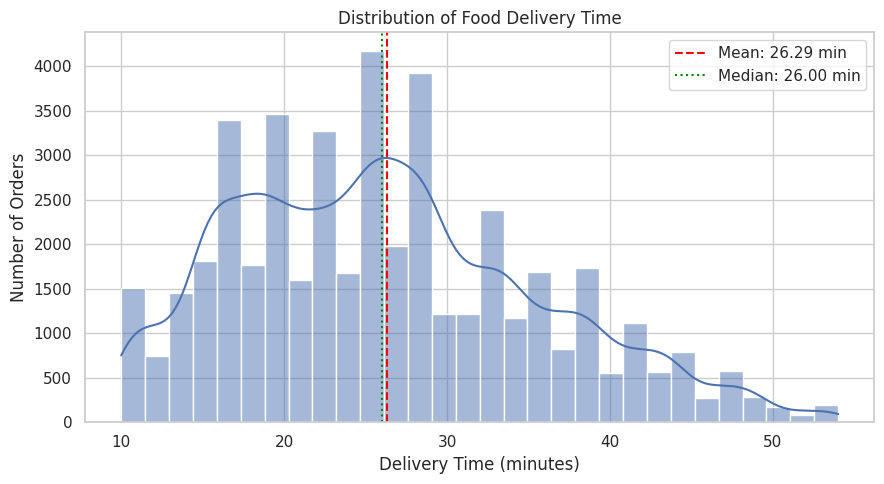

Mean: 26.29
Median: 26.0
Standard deviation: 9.38
Skewness: 0.486


In [6]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x=TARGET,
    bins=30,
    kde=True
)

plt.axvline(
    df[TARGET].mean(),
    color="red",
    linestyle="--",
    label=f"Mean: {df[TARGET].mean():.2f} min"
)

plt.axvline(
    df[TARGET].median(),
    color="green",
    linestyle=":",
    label=f"Median: {df[TARGET].median():.2f} min"
)

plt.title("Distribution of Food Delivery Time")
plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Number of Orders")
plt.legend()
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/01_delivery_time_distribution.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

print("Mean:", round(df[TARGET].mean(), 2))
print("Median:", round(df[TARGET].median(), 2))
print("Standard deviation:", round(df[TARGET].std(), 2))
print("Skewness:", round(df[TARGET].skew(), 3))


**Interpretation — Delivery-time distribution**

The target distribution summarizes typical delivery duration and its variability. Compare the mean and median to assess skewness; the right tail represents orders that take longer than usual. Use the values printed by the notebook rather than assuming every long delivery is an erroneous outlier.

**Outlier analysis — Boxplot**

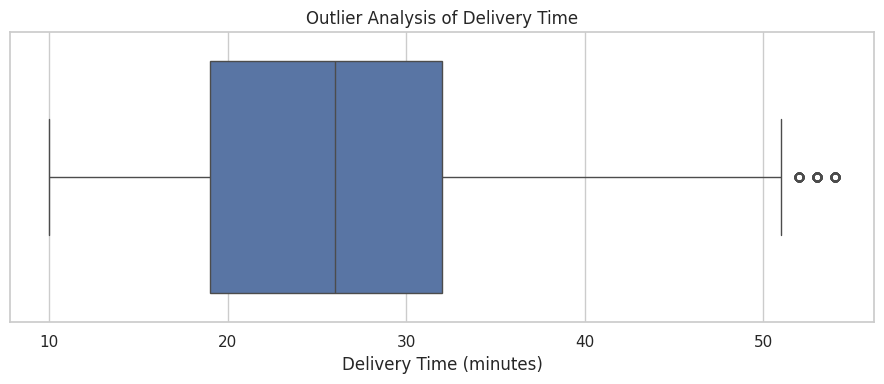

Lower bound: -0.5
Upper bound: 51.5
Potential outliers: 270
Outlier percentage: 0.59 %


In [7]:
plt.figure(figsize=(9, 4))

sns.boxplot(x=df[TARGET])

plt.title("Outlier Analysis of Delivery Time")
plt.xlabel("Delivery Time (minutes)")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/02_delivery_time_boxplot.png", dpi=160)
plt.show()

Q1 = df[TARGET].quantile(0.25)
Q3 = df[TARGET].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df[TARGET] < lower_bound) |
    (df[TARGET] > upper_bound)
]

print("Lower bound:", round(lower_bound, 2))
print("Upper bound:", round(upper_bound, 2))
print("Potential outliers:", len(outliers))
print("Outlier percentage:", round(len(outliers) / len(df) * 100, 2), "%")

**Interpretation — Outlier analysis**

The boxplot highlights unusually short or long delivery times relative to the interquartile range. These observations should not automatically be removed: long delivery times may reflect genuine delays and remain relevant to the prediction task.

**Multivariate analysis — Correlation heatmap**

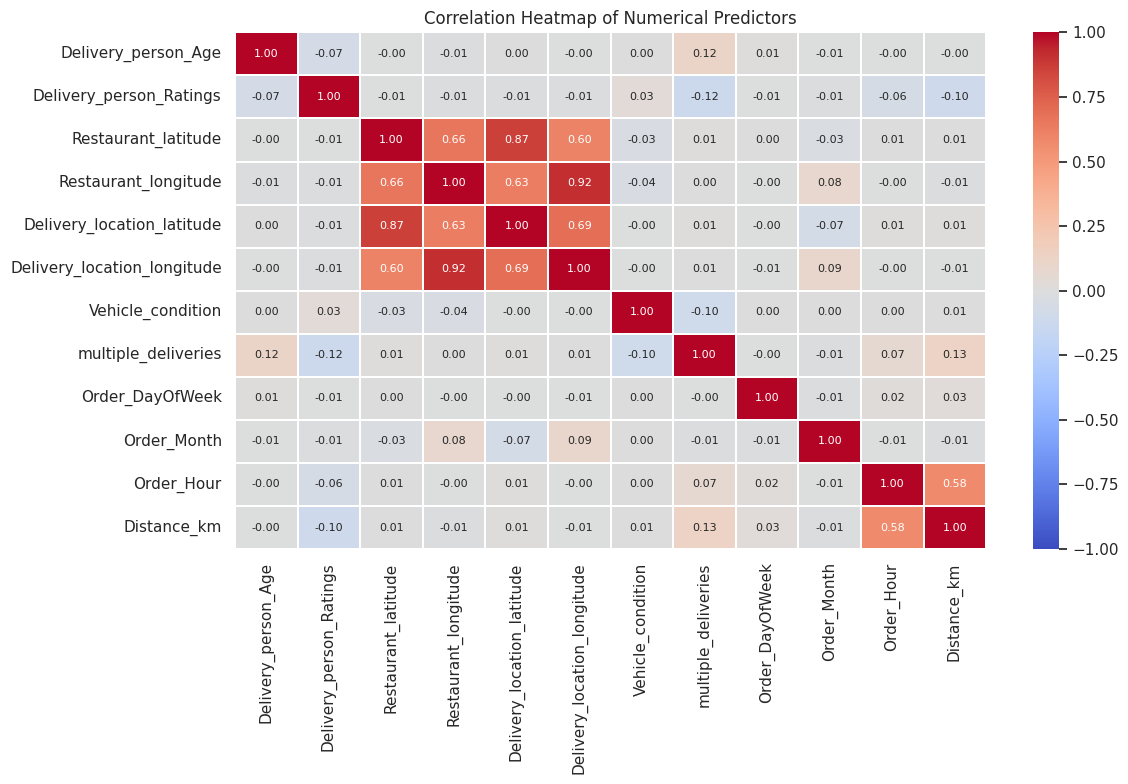

Features most strongly correlated with delivery time:


,Correlation
multiple_deliveries,0.387051
Delivery_person_Ratings,-0.338790
Distance_km,0.321703
Delivery_person_Age,0.299474
Vehicle_condition,-0.234398
Order_Hour,0.184378
Delivery_location_latitude,0.014243
Restaurant_latitude,0.013981
Order_Month,-0.012304
Restaurant_longitude,0.007821


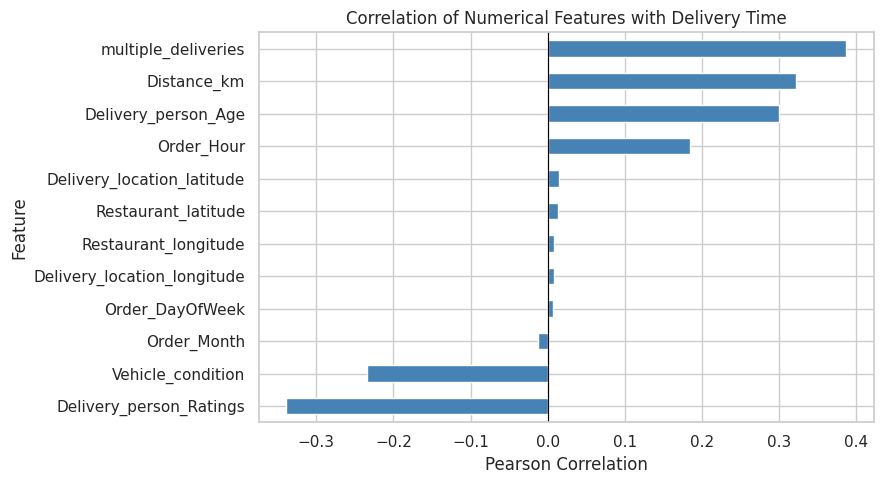

In [8]:
excluded_columns = [TARGET, "Pickup_Wait_Min"]

numeric_df = df.select_dtypes(include=np.number).drop(
    columns=[col for col in excluded_columns if col in df.columns],
    errors="ignore"
)

correlation = numeric_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    linewidths=0.3
)

plt.title("Correlation Heatmap of Numerical Predictors")
plt.tight_layout()
plt.savefig(
    f"{OUTPUT_DIR}/03_correlation_heatmap.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

target_numeric = df.select_dtypes(include=np.number).drop(
    columns=["Pickup_Wait_Min"],
    errors="ignore"
)

if TARGET in target_numeric.columns:
    target_correlation = (
        target_numeric.corr()[TARGET]
        .drop(TARGET)
        .sort_values(key=lambda x: x.abs(), ascending=False)
    )

    print("Features most strongly correlated with delivery time:")
    display(target_correlation.to_frame("Correlation"))

    plt.figure(figsize=(9, 5))
    target_correlation.sort_values().plot(
        kind="barh",
        color="steelblue"
    )
    plt.title("Correlation of Numerical Features with Delivery Time")
    plt.xlabel("Pearson Correlation")
    plt.ylabel("Feature")
    plt.axvline(0, color="black", linewidth=0.8)
    plt.tight_layout()
    plt.savefig(
        f"{OUTPUT_DIR}/04_target_correlation.png",
        dpi=160,
        bbox_inches="tight"
    )
    plt.show()


**Interpretation — Correlation heatmap**

Correlation indicates linear association between numeric variables, not causation. Review the strength and direction of relationships with delivery time, and remember that correlations near zero do not rule out nonlinear or categorical effects.

**Bivariate analysis — Distance versus delivery time**

In [9]:
print("========== DISTANCE QUALITY CHECK ==========")

print(df["Distance_km"].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
))

print("\nDistances greater than selected thresholds:")
for threshold in [50, 100, 500, 1000]:
    count = (df["Distance_km"] > threshold).sum()
    print(
        f"> {threshold} km: {count} rows "
        f"({count / len(df) * 100:.2f}%)"
    )

print("\nLargest estimated distances:")
display(
    df.nlargest(10, "Distance_km")[
        [
            "Restaurant_latitude",
            "Restaurant_longitude",
            "Delivery_location_latitude",
            "Delivery_location_longitude",
            "Distance_km",
            TARGET
        ]
    ]
)


========== DISTANCE QUALITY CHECK ==========
count    45162.000000
mean         9.735396
std          5.608508
min          1.465067
50%          9.220209
75%         13.681490
90%         19.087358
95%         19.975642
99%         20.557751
max         20.969489
Name: Distance_km, dtype: float64

Distances greater than selected thresholds:
> 50 km: 0 rows (0.00%)
> 100 km: 0 rows (0.00%)
> 500 km: 0 rows (0.00%)
> 1000 km: 0 rows (0.00%)

Largest estimated distances:


,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Distance_km,Time_taken(min)
912,25.443994,81.860187,25.583994,82.000187,20.969489,26
15710,25.443994,81.860187,25.583994,82.000187,20.969489,12
25926,25.443994,81.860187,25.583994,82.000187,20.969489,33
16640,25.449659,81.839744,25.589659,81.979744,20.969045,20
16787,25.449659,81.839744,25.589659,81.979744,20.969045,46
25476,25.449659,81.839744,25.589659,81.979744,20.969045,18
11194,25.449872,81.836167,25.589872,81.976167,20.969028,40
19738,25.449872,81.836167,25.589872,81.976167,20.969028,34
30265,25.449872,81.836167,25.589872,81.976167,20.969028,23
11436,25.450317,81.831681,25.590317,81.971681,20.968994,29


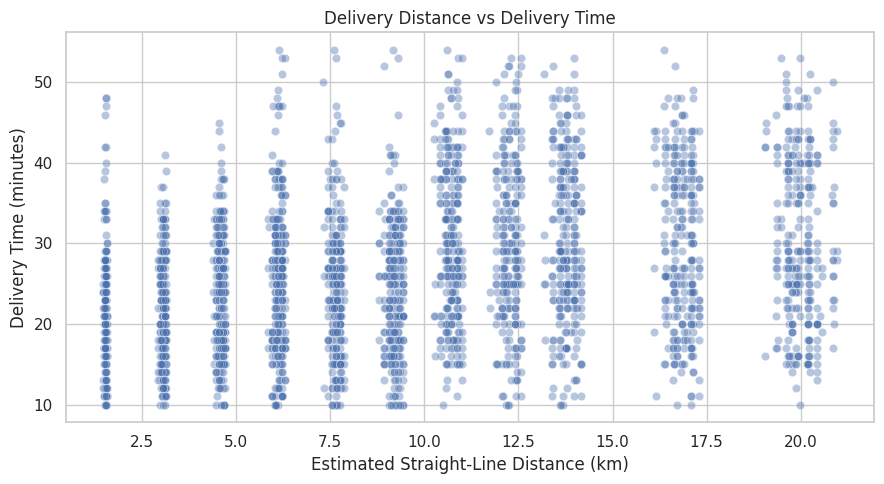

In [10]:
plot_data = df[["Distance_km", TARGET]].dropna()

if len(plot_data) > 3000:
    plot_data = plot_data.sample(3000, random_state=42)

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=plot_data,
    x="Distance_km",
    y=TARGET,
    alpha=0.4
)

plt.title("Delivery Distance vs Delivery Time")
plt.xlabel("Estimated Straight-Line Distance (km)")
plt.ylabel("Delivery Time (minutes)")
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/04_distance_vs_delivery_time.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()


**Interpretation — Distance and delivery time**

The scatterplot helps assess whether longer restaurant-to-customer distances tend to correspond to longer delivery times. Distance is a straight-line Haversine estimate, not the actual road route, and suspicious distances are treated as missing during feature engineering.

**Categorical analysis — Traffic density**

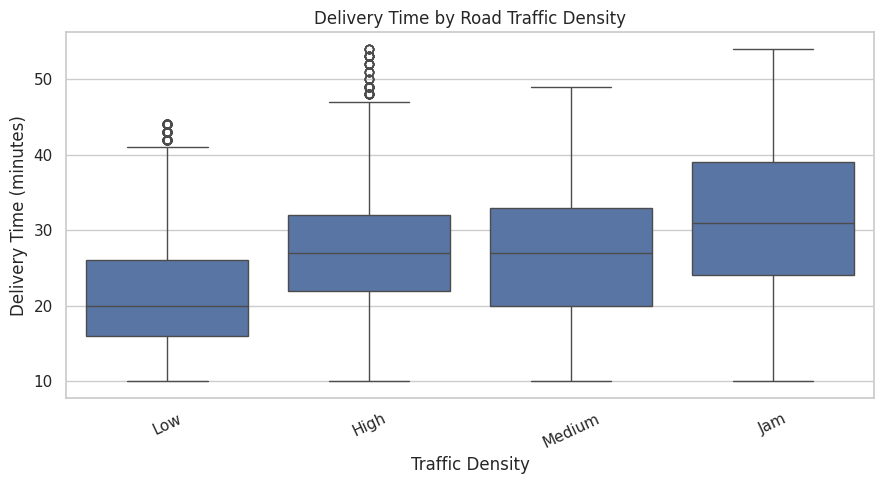

,count,mean,median,std
Road_traffic_density,,,,
High,4425,27.24,27.0,8.4
Jam,14143,31.18,31.0,9.94
Low,15477,21.27,20.0,6.8
Medium,10947,26.7,27.0,8.56


In [11]:
traffic_col = "Road_traffic_density"

if traffic_col in df.columns:

    plt.figure(figsize=(9, 5))

    order = (
        df.groupby(traffic_col)[TARGET]
        .median()
        .sort_values()
        .index
    )

    sns.boxplot(
        data=df,
        x=traffic_col,
        y=TARGET,
        order=order
    )

    plt.title("Delivery Time by Road Traffic Density")
    plt.xlabel("Traffic Density")
    plt.ylabel("Delivery Time (minutes)")
    plt.xticks(rotation=25)

    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/05_traffic_vs_delivery_time.png", dpi=160)
    plt.show()

    display(
        df.groupby(traffic_col)[TARGET]
        .agg(["count", "mean", "median", "std"])
        .round(2)
    )

else:
    print("Traffic density column not found.")

**Interpretation — Traffic density**

Compare the median delivery times across traffic categories. Higher values for heavier traffic would be consistent with traffic being associated with longer delivery times, but this grouped analysis alone does not establish causation.

**Categorical analysis — Weather conditions**

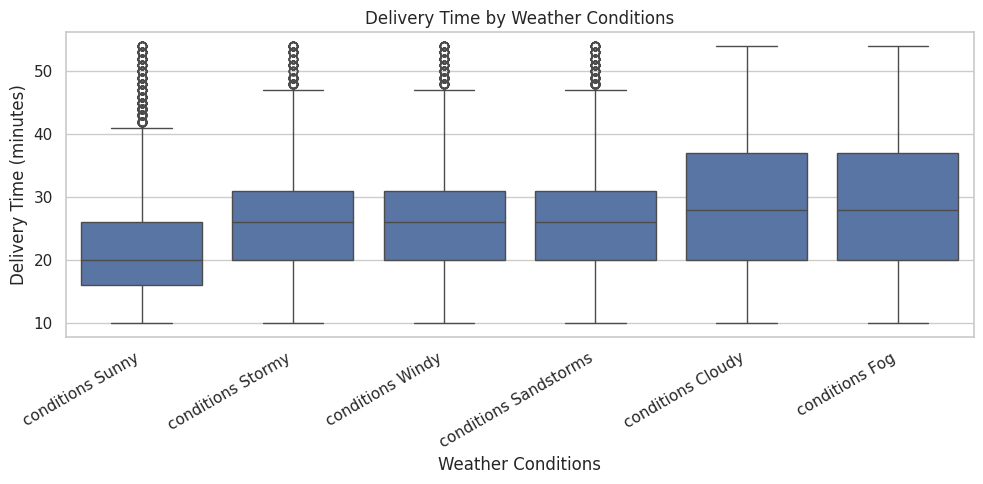

Missing weather values excluded: 616


,count,mean,median,std
Weatherconditions,,,,
conditions Cloudy,7536,28.92,28.0,10.08
conditions Fog,7654,28.92,28.0,10.13
conditions Sandstorms,7495,25.88,26.0,8.62
conditions Stormy,7586,25.87,26.0,8.47
conditions Sunny,7284,21.86,20.0,8.33
conditions Windy,7422,26.12,26.0,8.62


In [12]:
if weather_col in df.columns:

    weather_data = df.dropna(subset=[weather_col, TARGET]).copy()

    order = (
        weather_data.groupby(weather_col)[TARGET]
        .median()
        .sort_values()
        .index
    )

    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=weather_data,
        x=weather_col,
        y=TARGET,
        order=order
    )

    plt.title("Delivery Time by Weather Conditions")
    plt.xlabel("Weather Conditions")
    plt.ylabel("Delivery Time (minutes)")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/06_weather_vs_delivery_time.png",
        dpi=160,
        bbox_inches="tight"
    )
    plt.show()

    print("Missing weather values excluded:", df[weather_col].isna().sum())

    display(
        weather_data.groupby(weather_col)[TARGET]
        .agg(["count", "mean", "median", "std"])
        .round(2)
    )

else:
    print("Weather column not found.")

**Interpretation — Weather conditions**

Compare delivery-time distributions across the observed weather categories. Differences may suggest that weather is associated with delivery duration; interpret categories alongside their sample sizes and avoid causal claims.

**Categorical analysis — Vehicle type**

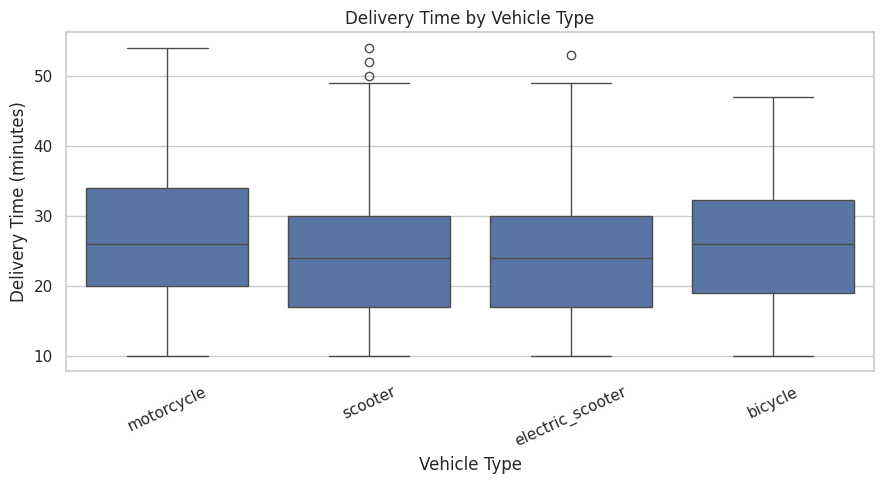

Delivery-time statistics by vehicle type:


,count,mean,median,std
Type_of_vehicle,,,,
bicycle,68,26.43,26.0,9.26
electric_scooter,3814,24.47,24.0,8.61
motorcycle,26435,27.61,26.0,9.65
scooter,15276,24.48,24.0,8.7


In [13]:
vehicle_col = "Type_of_vehicle"

if vehicle_col in df.columns:

    plt.figure(figsize=(9, 5))

    sns.boxplot(
        data=df,
        x=vehicle_col,
        y=TARGET
    )

    plt.title("Delivery Time by Vehicle Type")
    plt.xlabel("Vehicle Type")
    plt.ylabel("Delivery Time (minutes)")
    plt.xticks(rotation=25)
    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/07_vehicle_vs_delivery_time.png",
        dpi=160,
        bbox_inches="tight"
    )
    plt.show()

    print("Delivery-time statistics by vehicle type:")
    display(
        df.groupby(vehicle_col)[TARGET]
        .agg(["count", "mean", "median", "std"])
        .round(2)
    )

else:
    print("Vehicle type column not found.")


**Interpretation — Vehicle type**

The boxplot compares delivery-time distributions across vehicle categories. Consider both medians and spread, and be cautious about conclusions from categories with small sample sizes.

**Additional statistical analysis**

In [14]:
print("========== DELIVERY-TIME DESCRIPTIVE STATISTICS ==========")

display(
    df[TARGET]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .to_frame("Value")
    .round(2)
)

group_columns = ["City", "Festival", "multiple_deliveries"]

for col in group_columns:
    if col in df.columns:
        print(f"\n========== DELIVERY TIME BY {col.upper()} ==========")
        print("Missing category values:", df[col].isna().sum())

        display(
            df.groupby(col, dropna=True)[TARGET]
            .agg(["count", "mean", "median", "std"])
            .round(2)
        )


========== DELIVERY-TIME DESCRIPTIVE STATISTICS ==========


,Value
count,45593.00
mean,26.29
median,26.00
std,9.38
min,10.00
max,54.00



========== DELIVERY TIME BY CITY ==========
Missing category values: 1200


,count,mean,median,std
City,,,,
Metropolitian,34093,27.32,27.0,9.18
Semi-Urban,164,49.73,49.0,2.69
Urban,10136,22.98,22.0,8.87



========== DELIVERY TIME BY FESTIVAL ==========
Missing category values: 228


,count,mean,median,std
Festival,,,,
No,44469,25.98,25.0,9.01
Yes,896,45.52,45.0,4.0



========== DELIVERY TIME BY MULTIPLE_DELIVERIES ==========
Missing category values: 993


,count,mean,median,std
multiple_deliveries,,,,
0,14095,22.88,22.0,8.77
1,28159,26.86,26.0,8.54
2,1985,40.45,40.0,4.92
3,361,47.82,48.0,3.48


**Interpretation — Grouped statistics**

Use the printed group counts, means, medians, and standard deviations to identify potentially important patterns in city, festival, and multiple-delivery groups. Groups with very different sample sizes should not be compared using means alone.

**Preprocessing for deep learning**

In [15]:
X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].astype(float).copy()

id_columns = []

for col in X.columns:

    unique_ratio = X[col].nunique(dropna=True) / max(len(X), 1)

    if (
        col.lower() in ["id", "delivery_person_id"]
        or (
            unique_ratio > 0.95
            and ("id" in col.lower() or "code" in col.lower())
        )
    ):
        id_columns.append(col)

X = X.drop(columns=id_columns, errors="ignore")

print("Removed identifier columns:", id_columns)
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Removed identifier columns: []
Feature shape: (45593, 18)
Target shape: (45593,)


In [16]:
print("Dataset shape:", df.shape)
print("\nCurrent columns:")
for col in df.columns:
    print("-", col)

print("\nTarget column:", TARGET)
print("Predictor count:", df.drop(columns=[TARGET]).shape[1])


Dataset shape: (45593, 19)

Current columns:
- Delivery_person_Age
- Delivery_person_Ratings
- Restaurant_latitude
- Restaurant_longitude
- Delivery_location_latitude
- Delivery_location_longitude
- Weatherconditions
- Road_traffic_density
- Vehicle_condition
- Type_of_order
- Type_of_vehicle
- multiple_deliveries
- Festival
- City
- Time_taken(min)
- Order_DayOfWeek
- Order_Month
- Order_Hour
- Distance_km

Target column: Time_taken(min)
Predictor count: 18


**Split the data into training, validation and test sets**

In [17]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42
)

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

print("\nTraining percentage:", round(len(X_train) / len(X) * 100, 2))
print("Validation percentage:", round(len(X_val) / len(X) * 100, 2))
print("Testing percentage:", round(len(X_test) / len(X) * 100, 2))

Training records: 31915
Validation records: 6839
Testing records: 6839

Training percentage: 70.0
Validation percentage: 15.0
Testing percentage: 15.0


**Handle missing values, encode categories and standardize features**

In [18]:
X_train = X_train.copy().astype(object).replace({pd.NA: np.nan})
X_val = X_val.copy().astype(object).replace({pd.NA: np.nan})
X_test = X_test.copy().astype(object).replace({pd.NA: np.nan})

numeric_features = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude",
    "Vehicle_condition",
    "multiple_deliveries",
    "Order_DayOfWeek",
    "Order_Month",
    "Order_Hour",
    "Distance_km"
]

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

missing_numeric = [
    col for col in numeric_features
    if col not in X_train.columns
]

if missing_numeric:
    raise ValueError(
        f"Missing numerical features: {missing_numeric}"
    )

for data in [X_train, X_val, X_test]:
    for col in numeric_features:
        data[col] = pd.to_numeric(data[col], errors="coerce")

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(
    X_train
).astype(np.float32)

X_val_processed = preprocessor.transform(
    X_val
).astype(np.float32)

X_test_processed = preprocessor.transform(
    X_test
).astype(np.float32)

y_train_processed = y_train.to_numpy(dtype=np.float32)
y_val_processed = y_val.to_numpy(dtype=np.float32)
y_test_processed = y_test.to_numpy(dtype=np.float32)

print("========== PREPROCESSING RESULTS ==========")
print("Training matrix:", X_train_processed.shape)
print("Validation matrix:", X_val_processed.shape)
print("Testing matrix:", X_test_processed.shape)

print("\nTarget shapes:")
print("Training:", y_train_processed.shape)
print("Validation:", y_val_processed.shape)
print("Testing:", y_test_processed.shape)

for name, matrix in [
    ("Training", X_train_processed),
    ("Validation", X_val_processed),
    ("Testing", X_test_processed)
]:
    print(
        f"{name} contains NaN:",
        np.isnan(matrix).any()
    )
    print(
        f"{name} contains infinity:",
        np.isinf(matrix).any()
    )

assert X_train_processed.shape[1] == X_val_processed.shape[1]
assert X_train_processed.shape[1] == X_test_processed.shape[1]
assert np.isfinite(X_train_processed).all()
assert np.isfinite(X_val_processed).all()
assert np.isfinite(X_test_processed).all()

print("\nPreprocessing completed successfully.")


========== PREPROCESSING RESULTS ==========
Training matrix: (31915, 35)
Validation matrix: (6839, 35)
Testing matrix: (6839, 35)

Target shapes:
Training: (31915,)
Validation: (6839,)
Testing: (6839,)
Training contains NaN: False
Training contains infinity: False
Validation contains NaN: False
Validation contains infinity: False
Testing contains NaN: False
Testing contains infinity: False

Preprocessing completed successfully.


**Deep learning model**

In [19]:
tf.keras.backend.clear_session()
tf.random.set_seed(42)

model = Sequential([
    tf.keras.Input(shape=(X_train_processed.shape[1],)),

    Dense(64, activation="relu"),

    Dropout(0.20),

    Dense(32, activation="relu"),

    Dense(1, activation="linear")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,417 (17.25 KB)

 Trainable params: 4,417 (17.25 KB)

 Non-trainable params: 0 (0.00 B)

**Train the model**

In [20]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = model.fit(
    X_train_processed,
    y_train_processed,

    validation_data=(
        X_val_processed,
        y_val_processed
    ),

    epochs=60,
    batch_size=64,

    callbacks=[early_stopping],

    verbose=1
)

print("Model training completed.")
print("Epochs actually completed:", len(history.history["loss"]))

Epoch 1/60
499/499 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 115.1072 - mae: 7.5927 - val_loss: 36.4824 - val_mae: 4.7997
Epoch 2/60
499/499 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 39.6820 - mae: 4.9884 - val_loss: 33.7417 - val_mae: 4.6112
Epoch 3/60
499/499 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 36.8554 - mae: 4.8040 - val_loss: 30.9626 - val_mae: 4.3964
Epoch 4/60
499/499 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 34.3280 - mae: 4.6194 - val_loss: 29.7585 - val_mae: 4.2907
Epoch 5/60
499/499 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 33.3792 - mae: 4.5490 - val_loss: 28.0666 - val_mae: 4.1702
Epoch 6/60
499/499 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 32.1695 - mae: 4.4703 - val_loss: 27.4030 - val_mae: 4.1138
Epoch 7/60
499/499 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 31.5318 - mae: 4.4084 - val_loss: 27.1186 - val_mae: 4.0939
Epoch 8/60
499/499 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 30.8081 - mae: 4.3697 - val_loss: 26.5666 - val_mae: 4.0568
Epoch 9/60
499/499 ━━━━━━━━━━━━━━━━━━━━

**Model Evaluation**

In [21]:
nn_val_predictions = model.predict(
    X_val_processed,
    verbose=0
).flatten()

nn_val_mae = mean_absolute_error(
    y_val_processed,
    nn_val_predictions
)

nn_val_rmse = np.sqrt(
    mean_squared_error(
        y_val_processed,
        nn_val_predictions
    )
)

nn_val_r2 = r2_score(
    y_val_processed,
    nn_val_predictions
)

nn_validation_metrics = pd.DataFrame({
    "Metric": ["MAE (minutes)", "RMSE (minutes)", "R²"],
    "Value": [nn_val_mae, nn_val_rmse, nn_val_r2]
})

print("========== NEURAL NETWORK VALIDATION RESULTS ==========")
display(nn_validation_metrics.round(4))

========== NEURAL NETWORK VALIDATION RESULTS ==========


,Metric,Value
0,MAE (minutes),3.2460
1,RMSE (minutes),4.1089
2,R²,0.8118


In [22]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train_processed, y_train_processed)

rf_model = RandomForestRegressor(
    n_estimators=150,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train_processed)

print("Baseline and Random Forest training completed.")
print("Model comparison and selection will use validation data only.")

Baseline and Random Forest training completed.
Model comparison and selection will use validation data only.


**Training loss versus epoch**

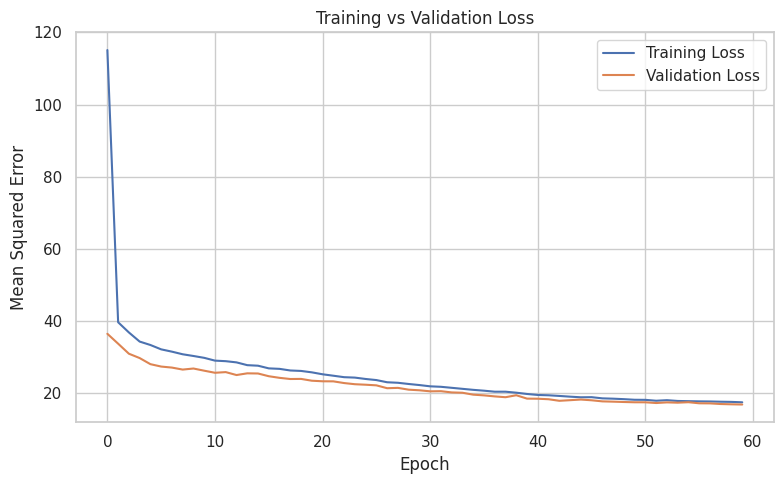

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/08_loss_vs_epoch.png", dpi=160)
plt.show()

**Interpretation — Training and validation loss**

A downward trend in both curves indicates learning. If training loss continues to fall while validation loss rises substantially, that can indicate overfitting. The best weights are restored by early stopping.

**Accuracy-related visualization — MAE versus epoch**

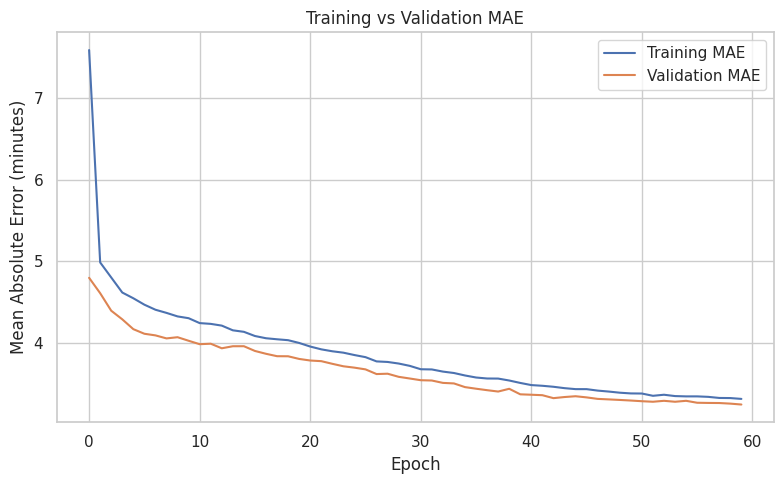

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["mae"],
    label="Training MAE"
)

plt.plot(
    history.history["val_mae"],
    label="Validation MAE"
)

plt.title("Training vs Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("Mean Absolute Error (minutes)")
plt.legend()

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/09_mae_vs_epoch.png", dpi=160)
plt.show()

**Interpretation — Training and validation MAE**

MAE is measured in minutes, so lower values mean smaller average absolute errors. Similar training and validation curves suggest comparable performance on seen and held-out validation data.

**Actual versus predicted delivery time**

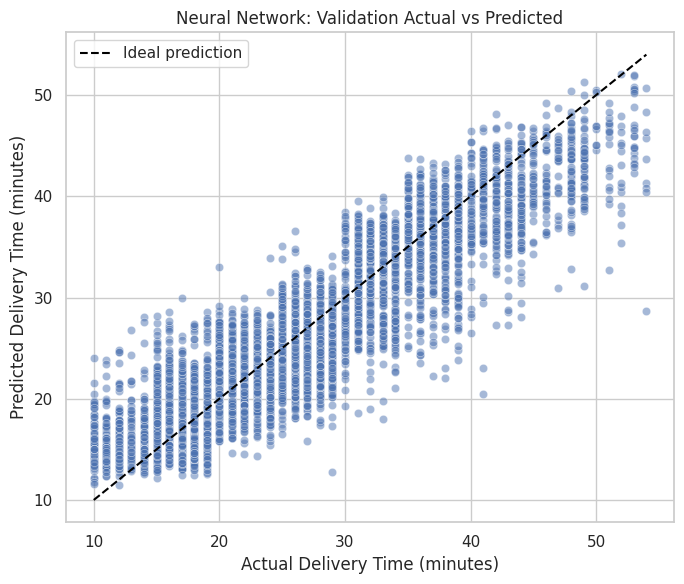

In [25]:
plt.figure(figsize=(7, 6))

sns.scatterplot(
    x=y_val_processed,
    y=nn_val_predictions,
    alpha=0.5
)

minimum = min(
    y_val_processed.min(),
    nn_val_predictions.min()
)

maximum = max(
    y_val_processed.max(),
    nn_val_predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    color="black",
    label="Ideal prediction"
)

plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.title("Neural Network: Validation Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.savefig(
    f"{OUTPUT_DIR}/10_actual_vs_predicted.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

**Interpretation — Neural-network validation predictions**

Points closer to the diagonal represent more accurate predictions. Systematic deviations above or below the line can indicate underprediction or overprediction in particular delivery-time ranges.

**Prediction error distribution**

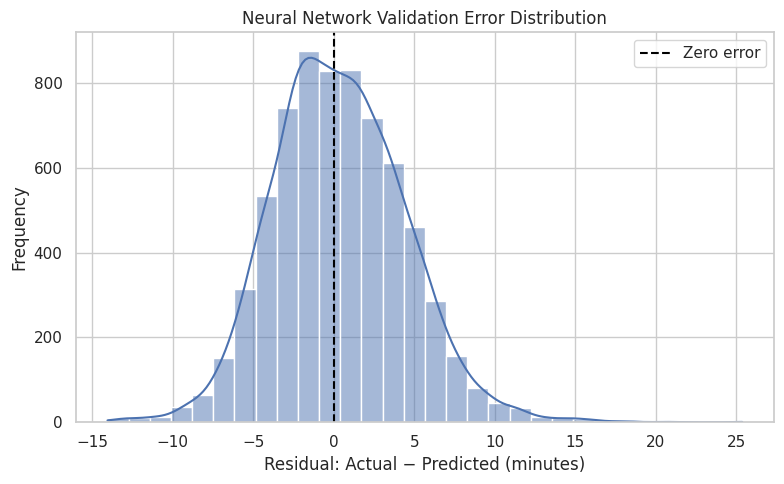

Mean validation residual: 0.345
Median absolute validation error: 2.711


In [26]:
nn_val_residuals = y_val_processed - nn_val_predictions

plt.figure(figsize=(8, 5))

sns.histplot(
    nn_val_residuals,
    bins=30,
    kde=True
)

plt.axvline(
    0,
    linestyle="--",
    color="black",
    label="Zero error"
)

plt.title("Neural Network Validation Error Distribution")
plt.xlabel("Residual: Actual − Predicted (minutes)")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.savefig(
    f"{OUTPUT_DIR}/11_error_distribution.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

print("Mean validation residual:", round(np.mean(nn_val_residuals), 3))
print(
    "Median absolute validation error:",
    round(np.median(np.abs(nn_val_residuals)), 3)
)

**Interpretation — Neural-network validation residuals**

Residuals are actual minus predicted delivery time. A distribution centered near zero suggests little overall bias; a wide distribution or long tails indicates some predictions have larger errors.

**Feature relationship analysis**

,Correlation with delivery time
multiple_deliveries,0.387051
Delivery_person_Ratings,-0.338790
Distance_km,0.321703
Delivery_person_Age,0.299474
Vehicle_condition,-0.234398
Order_Hour,0.184378
Delivery_location_latitude,0.014243
Restaurant_latitude,0.013981
Order_Month,-0.012304
Restaurant_longitude,0.007821


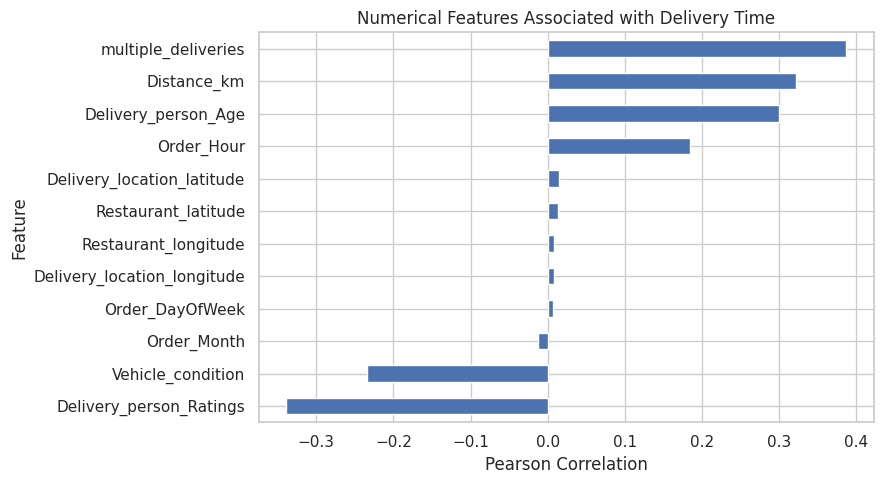

Pickup_Wait_Min present in df: False


In [27]:
numeric_features_df = df.select_dtypes(include=np.number)

excluded_features = [TARGET, "Pickup_Wait_Min"]

target_corr = (
    numeric_features_df
    .corr()[TARGET]
    .drop(labels=excluded_features, errors="ignore")
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

display(
    target_corr.to_frame("Correlation with delivery time")
)

plt.figure(figsize=(9, 5))

target_corr.head(12).sort_values().plot(kind="barh")

plt.title("Numerical Features Associated with Delivery Time")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")

plt.tight_layout()
plt.savefig(
    f"{OUTPUT_DIR}/12_feature_correlations.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Pickup_Wait_Min present in df:", "Pickup_Wait_Min" in df.columns)


**Interpretation — Numerical feature correlations**

The strongest absolute Pearson correlations identify numeric variables with the clearest linear relationships to delivery time in this dataset. Correlation is not feature importance and does not capture all nonlinear effects.

**Compare models using validation data**

The baseline, Random Forest, and neural network are compared using the validation split. The model with the lowest validation MAE is selected. The test split is reserved for the final, one-time evaluation.

In [28]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
import numpy as np
import pandas as pd

nn_val_predictions = model.predict(
    X_val_processed, verbose=0
).flatten()

rf_val_predictions = rf_model.predict(X_val_processed)

baseline_val_predictions = baseline.predict(X_val_processed)

validation_results = []

for name, pred in [
    ("Mean Baseline", baseline_val_predictions),
    ("Random Forest", rf_val_predictions),
    ("Neural Network", nn_val_predictions)
]:
    validation_results.append({
        "Model": name,
        "MAE (minutes)": mean_absolute_error(
            y_val_processed, pred
        ),
        "RMSE (minutes)": np.sqrt(
            mean_squared_error(y_val_processed, pred)
        ),
        "R2": r2_score(y_val_processed, pred)
    })

validation_df = pd.DataFrame(validation_results)
validation_df = validation_df.sort_values(
    "MAE (minutes)"
).reset_index(drop=True)

display(validation_df.round(4))

validation_df.to_csv(
    f"{OUTPUT_DIR}/validation_model_comparison.csv",
    index=False
)

best_model_name = validation_df.loc[0, "Model"]

if best_model_name == "Random Forest":
    best_model = rf_model
elif best_model_name == "Neural Network":
    best_model = model
else:
    best_model = baseline

print("Selected model:", best_model_name)
print("Selection criterion: Lowest validation MAE")


,Model,MAE (minutes),RMSE (minutes),R2
0,Random Forest,3.2452,4.0860,0.8138
1,Neural Network,3.2460,4.1089,0.8118
2,Mean Baseline,7.6596,9.4702,-0.0000


Selected model: Random Forest
Selection criterion: Lowest validation MAE


**Final evaluation on the test set**

In [29]:
final_predictions = best_model.predict(X_test_processed)

final_predictions = np.asarray(final_predictions).reshape(-1)

final_mae = mean_absolute_error(
    y_test_processed, final_predictions
)

final_rmse = np.sqrt(
    mean_squared_error(y_test_processed, final_predictions)
)

final_r2 = r2_score(
    y_test_processed, final_predictions
)

final_metrics = pd.DataFrame({
    "Metric": [
        "MAE (minutes)",
        "RMSE (minutes)",
        "R2"
    ],
    "Value": [
        final_mae,
        final_rmse,
        final_r2
    ]
})

print("========== FINAL TEST RESULTS ==========")
print("Selected model:", best_model_name)
display(final_metrics.round(4))

print(f"MAE:  {final_mae:.2f} minutes")
print(f"RMSE: {final_rmse:.2f} minutes")
print(f"R2:   {final_r2:.4f}")

final_metrics.to_csv(
    f"{OUTPUT_DIR}/final_test_metrics.csv",
    index=False
)


========== FINAL TEST RESULTS ==========
Selected model: Random Forest


,Metric,Value
0,MAE (minutes),3.1619
1,RMSE (minutes),3.9963
2,R2,0.8140


MAE:  3.16 minutes
RMSE: 4.00 minutes
R2:   0.8140


**Interpretation — Final test evaluation**

MAE is the average absolute prediction error in minutes, RMSE penalizes larger errors more strongly, and R² describes the proportion of target variance explained relative to a mean-prediction baseline. These metrics should be reported only after the model has been selected using validation data.

**Actual vs predicted for the selected model**

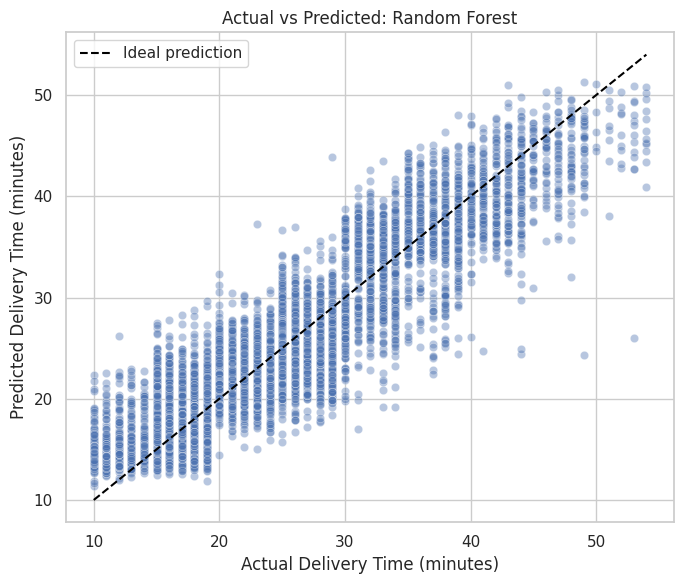

In [30]:
plt.figure(figsize=(7, 6))

sns.scatterplot(
    x=y_test_processed,
    y=final_predictions,
    alpha=0.4
)

minimum = min(
    y_test_processed.min(),
    final_predictions.min()
)

maximum = max(
    y_test_processed.max(),
    final_predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    color="black",
    label="Ideal prediction"
)

plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.title(f"Actual vs Predicted: {best_model_name}")
plt.legend()
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/13_final_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


**Interpretation — Final test predictions**

Points near the diagonal indicate agreement between predicted and actual delivery times on the held-out test set. This plot provides a visual check for systematic prediction errors across the target range.

**Final residual analysis**

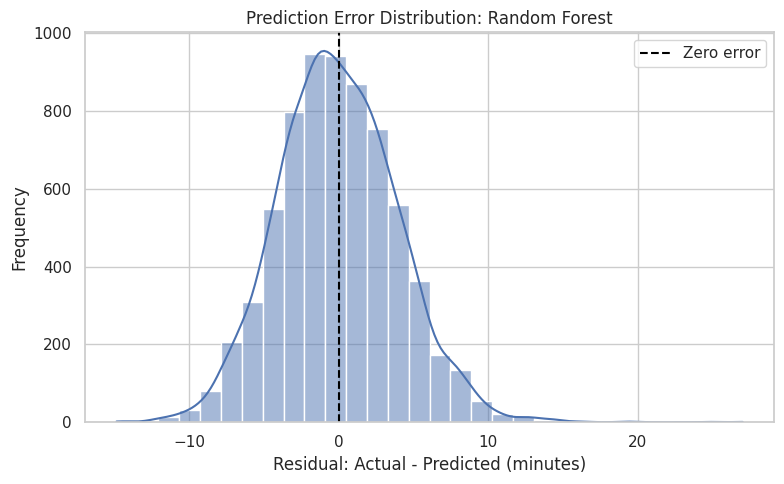

Mean residual: -0.054
Median absolute error: 2.669


In [31]:
final_residuals = y_test_processed - final_predictions

plt.figure(figsize=(8, 5))

sns.histplot(
    final_residuals,
    bins=30,
    kde=True
)

plt.axvline(
    0,
    linestyle="--",
    color="black",
    label="Zero error"
)

plt.title(f"Prediction Error Distribution: {best_model_name}")
plt.xlabel("Residual: Actual - Predicted (minutes)")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/14_final_residual_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Mean residual:", round(np.mean(final_residuals), 3))
print(
    "Median absolute error:",
    round(np.median(np.abs(final_residuals)), 3)
)


**Interpretation — Final test residuals**

Residuals centered around zero indicate limited average bias. The distribution's spread and tails reveal the frequency and size of prediction errors on the held-out test data.